Listo ✓
(1096, 3)


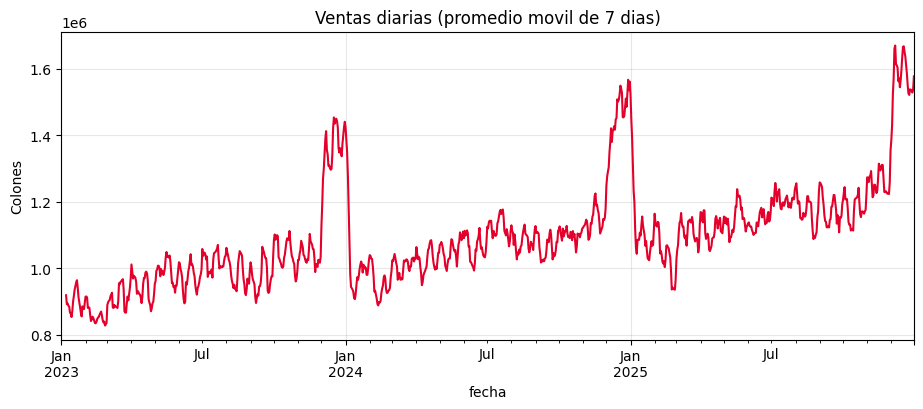

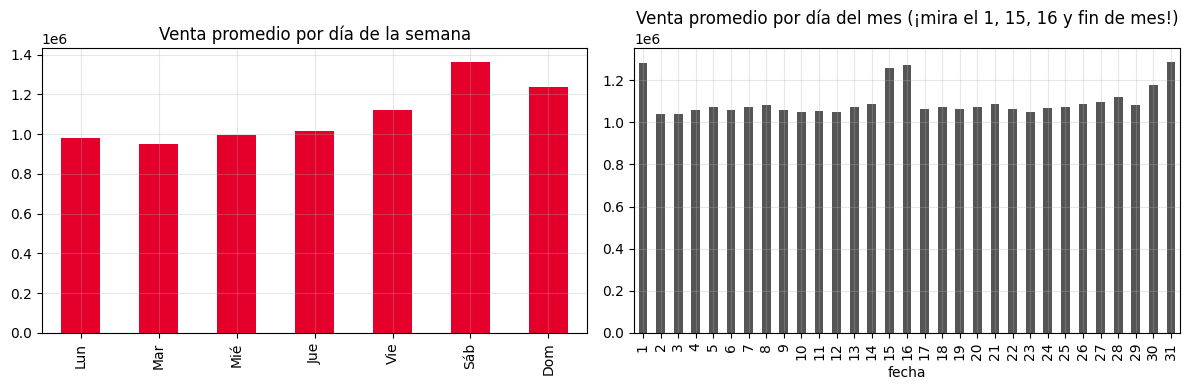

Entrenamiento : 1004 dias | Prueba : 92 dias
Línea base → error promedio: ₡143,983 por día  (10.7%)
Crecimiento por día: ₡247  →  por año: ₡89,981
Efecto de una promoción: +₡152,538
Efecto de quincena:      +₡193,649


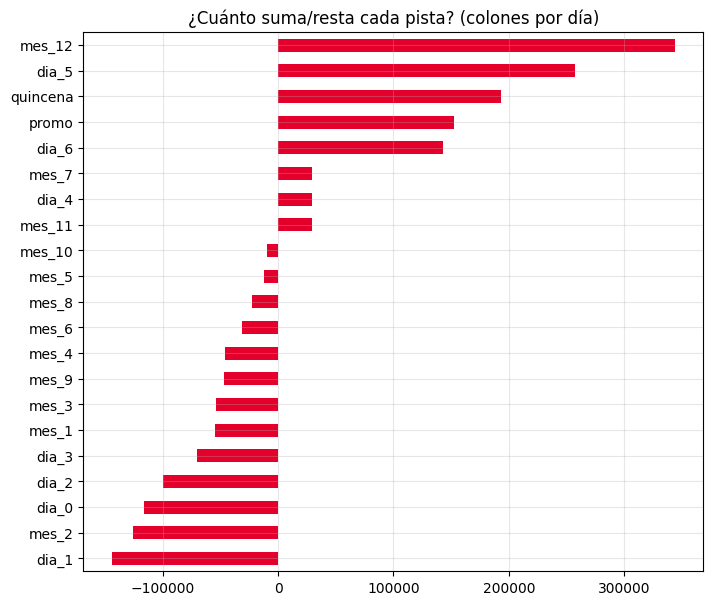

Venta total esperada en enero 2026: ₡37,070,000


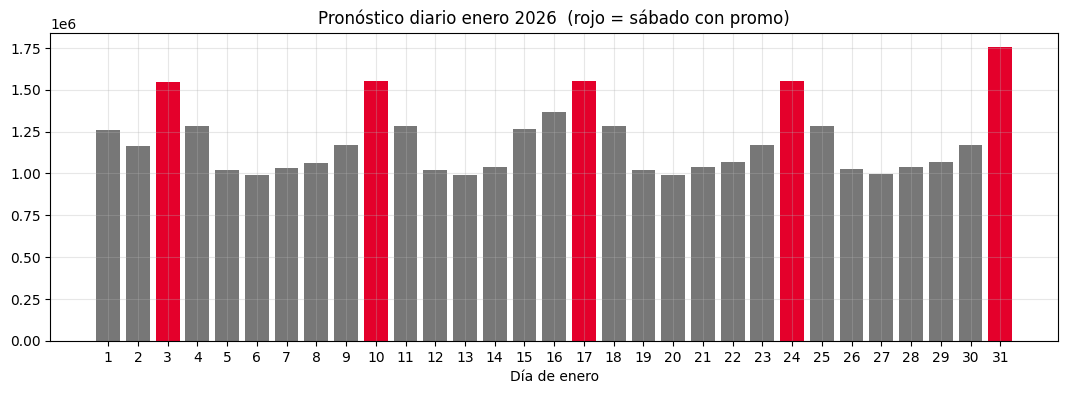

In [7]:
#Caso 1 Predicion de Ventas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.float_format", lambda x: f"{x:,.0f}")
print("Listo ✓")

#Paso 1 Crear los datos del supermercado.
rng = np.random.default_rng(42)
fechas = pd.date_range("2023-01-01", "2025-12-31", freq="D")
n = len(fechas)

dia_semana = fechas.dayofweek  # 0 = lunes  6=domingo
mes = fechas.month
dia = fechas.day
fin_de_mes = fechas.is_month_end

efecto_dia = np.array([0.90, 0.88, 0.92, 0.95, 1.05, 1.25, 1.15])[dia_semana]
efecto_mes = np.array([0.95, 0.88, 0.95, 0.97, 1.00, 0.98, 1.02, 0.98, 0.96, 0.99, 1.03, 1.30])[mes - 1]
quincena = ((dia == 15) | (dia == 16) | fin_de_mes | (dia == 1)).astype(int)
promo = (rng.random(n) < 0.12).astype(int)  # ~12 % de los días hay promo

tendencia = np.arange(n)
base = 900_000 + 250 * tendencia
ventas = base * efecto_dia * efecto_mes * (1 + 0.18 * quincena) * (1 + 0.15 * promo)
ventas = ventas * rng.normal(1, 0.05, n)
df = pd.DataFrame({
    "fecha": fechas,
    "promo": promo,
    "ventas": ventas.round(-2),
})
print(df.shape)
df.head(10)

ax = df.set_index("fecha")["ventas"].rolling(7).mean().plot(color="#E4002B", lw=1.5)
ax.set_title("Ventas diarias (promedio movil de 7 dias)")
ax.set_ylabel("Colones")
plt.show()

#------------------------------------------------------------

nombres = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df.groupby(df["fecha"].dt.dayofweek)["ventas"].mean().set_axis(nombres).plot.bar(
    ax=axes[0], color="#E4002B"
)
axes[0].set_title("Venta promedio por día de la semana")

df.groupby(df["fecha"].dt.day)["ventas"].mean().plot.bar(
    ax=axes[1], color="#555555"
)
axes[1].set_title("Venta promedio por día del mes (¡mira el 1, 15, 16 y fin de mes!)")
plt.tight_layout()
plt.show()

def crear_pistas(tabla, fecha_inicio="2023-01-01"):
    t = pd.DataFrame(index=tabla.index)
    f = tabla["fecha"]

    t["tendencia"] = (f - pd.Timestamp(fecha_inicio)).dt.days
    t["quincena"] = (f.dt.day.isin([1, 15, 16]) | f.dt.is_month_end).astype(int)
    t["promo"] = tabla["promo"]

    t = t.join(pd.get_dummies(f.dt.dayofweek, prefix="dia").astype(int))
    t = t.join(pd.get_dummies(f.dt.month, prefix="mes").astype(int))

    return t


X = crear_pistas(df)
y = df["ventas"]

X.head()


#Paso 4 Separar respetando el tiempo.

corte = df["fecha"] < "2025-10-01"

X_train, X_test = X[corte], X[~corte]
y_train, y_test = y[corte], y[~corte]

print(f"Entrenamiento : {len(X_train)} dias | Prueba : {len(X_test)} dias")

#Paso 5 La linea base

pred_base = df["ventas"].shift(7)[~corte]  # misma venta de hace 7 días

mae_base = mean_absolute_error(y_test, pred_base)

print(f"Línea base → error promedio: ₡{mae_base:,.0f} por día  ({mae_base / y_test.mean():.1%})")

#Paso 6 Entrenar dos modelos y compararlos

modelos = {
    "Regresión lineal": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42),
}

resultados = {"Línea base (semana pasada)": mae_base}
predicciones = {}

for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    p = modelo.predict(X_test)
    predicciones[nombre] = p
    resultados[nombre] = mean_absolute_error(y_test, p)

tabla = pd.DataFrame({"Error promedio diario (₡)": resultados})

tabla["Error %"] = (
    tabla["Error promedio diario (₡)"] / y_test.mean() * 100
).map("{:.1f} %".format)

tabla.sort_values("Error promedio diario (₡)")

#Paso 7 Que aprendio el modelo

lr = modelos["Regresión lineal"]

coef = pd.Series(lr.coef_, index=X.columns)

print(f"Crecimiento por día: ₡{coef['tendencia']:,.0f}  →  por año: ₡{coef['tendencia']*365:,.0f}")

print(f"Efecto de una promoción: +₡{coef['promo']:,.0f}")

print(f"Efecto de quincena:      +₡{coef['quincena']:,.0f}")

coef.drop(["tendencia"]).sort_values().plot.barh(
    figsize=(8, 7),
    color="#E4002B"
)

plt.title("¿Cuánto suma/resta cada pista? (colones por día)")

plt.show()

#Paso 8 Predecir el futuro : enero 2026

lr_final = LinearRegression().fit(X, y)

enero = pd.DataFrame({
    "fecha": pd.date_range("2026-01-01", "2026-01-31", freq="D")
})

enero["promo"] = (enero["fecha"].dt.dayofweek == 5).astype(int)  # promo los sábados

X_enero = crear_pistas(enero).reindex(columns=X.columns, fill_value=0)

enero["pronostico"] = lr_final.predict(X_enero).round(-3)

print(f"Venta total esperada en enero 2026: ₡{enero['pronostico'].sum():,.0f}")

enero.head(10)

fig, ax = plt.subplots(figsize=(13, 4))

ax.bar(
    enero["fecha"].dt.day,
    enero["pronostico"],
    color=np.where(enero["promo"] == 1, "#E4002B", "#777777")
)

ax.set_xticks(range(1, 32))

ax.set_xlabel("Día de enero")

ax.set_title("Pronóstico diario enero 2026  (rojo = sábado con promo)")

plt.show()